# 1D Second-Order Wave Equation: Explicit Leap-Frog Scheme

## 1. Theory & CFL Stability Analysis
The 1D second-order wave equation is:
$$\frac{\partial^2 \psi}{\partial t^2} = c^2 \frac{\partial^2 \psi}{\partial x^2}$$

**Explicit Leap-Frog Discretization:**
$$\psi_i^{n+1} = k^2(\psi_{i+1}^n + \psi_{i-1}^n) + 2(1 - k^2)\psi_i^n - \psi_i^{n-1}, \quad k = \frac{c \Delta t}{\Delta x}$$

**CFL Condition & Exactness at $k = 1$:**
- Stability requires $k = \frac{c \Delta t}{\Delta x} \le 1$.
- When $k = 1$, the scheme simplifies to $\psi_i^{n+1} = \psi_{i+1}^n + \psi_{i-1}^n - \psi_i^{n-1}$, which has **zero truncation error** and exact numerical propagation.

**Initial Velocity Step:**
$$\psi_i^1 = (1 - k^2)\psi_i^0 + \frac{k^2}{2}(\psi_{i+1}^0 + \psi_{i-1}^0) + \Delta t v(x_i)$$

## 2. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 3.2)
2nd-Order Wave Equation with leap-frog scheme, magic time step $k = 1.0$, Taylor first-step with initial velocity, Dirichlet boundaries, and space-time heatmap.

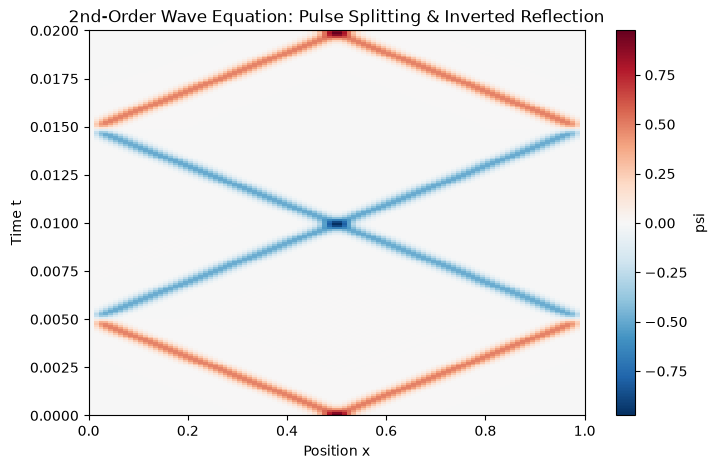

In [3]:
import numpy as np 
import matplotlib.pyplot as plt

# Parameters
N = 100
dx = 0.01
L = N * dx
c = 100.0             # Wave speed
dt = 1e-4             # Time step
k = c * dt / dx       # CFL = 1.0 (Exact discretization!)
assert k <= 1.0, f"CFL condition violated: k = {k} > 1!"

x = np.linspace(0, L, N)
t_end = 0.02
nt = int(round(t_end / dt))

# Initial Conditions: Gaussian packet at center
psi_0 = np.exp(-1000 * (x - L/2)**2)
psi_prev = psi_0.copy()
psi = np.zeros(N)

# First Step (Initial velocity v0 = 0)
v0 = np.zeros(N)
for i in range(1, N - 1):
    psi[i] = (k**2 / 2) * (psi_0[i+1] + psi_0[i-1]) + (1 - k**2) * psi_0[i] + dt * v0[i]

# Dirichlet boundary conditions
psi[0] = 0; psi[-1] = 0
psi_history = [psi_0.copy(), psi.copy()]

# Time stepping loop
for j in range(2, nt):
    psi_next = np.zeros(N)
    for i in range(1, N - 1):
        psi_next[i] = (k**2) * (psi[i+1] + psi[i-1]) + 2 * (1 - k**2) * psi[i] - psi_prev[i]
    psi_next[0] = 0; psi_next[-1] = 0
    psi_prev = psi.copy()
    psi = psi_next.copy()
    psi_history.append(psi.copy())

# Space-Time Heatmap
plt.figure(figsize=(8, 5))
plt.imshow(np.array(psi_history), aspect='auto', origin='lower',
           extent=[0, L, 0, t_end], cmap='RdBu_r', interpolation='nearest')
plt.colorbar(label='psi')
plt.xlabel('Position x'); plt.ylabel('Time t')
plt.title('2nd-Order Wave Equation: Pulse Splitting & Inverted Reflection')
plt.show()


## 3. PROFESSOR'S IN-CLASS CODE (from `n+1/2ndorderwaveeqn.ipynb`)
This is the code as directly written in `n+1/2ndorderwaveeqn.ipynb`.

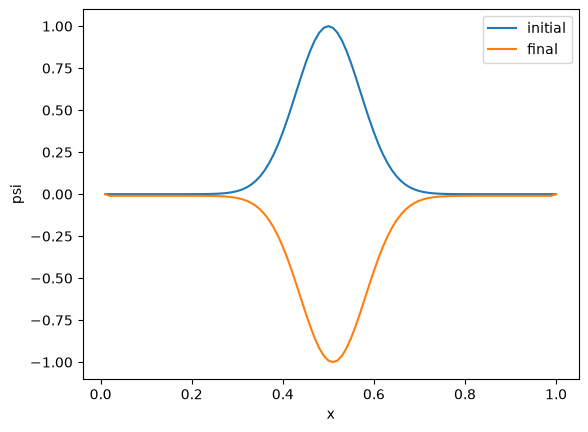

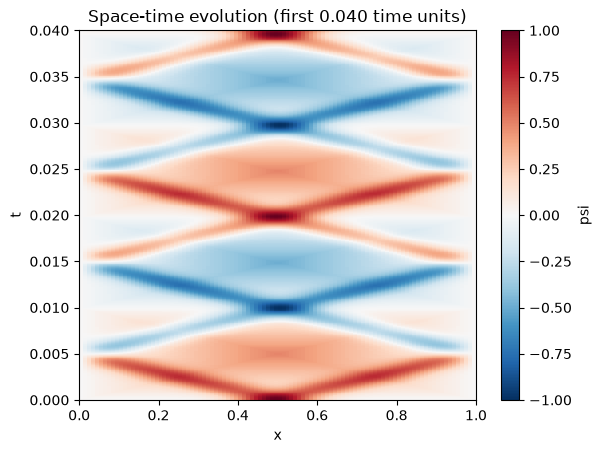

In [4]:
import numpy as np 
import matplotlib.pyplot as plt

# Parameters
N = 100
t_end = 100
dt = 10**(-4)
dx = 10**(-2)
L = N * dx
x = np.arange(dx, L+dx/2, dx)
v = 100
k = v * dt / dx
nt = int(round(t_end / dt))
heat_steps = 400       # steps recorded for the heatmap (~2 bounce periods)
v_not = 0

# Initial Conditions
psi = np.exp(-100 * (x - L/2)**2)
psi_0 = psi.copy()
psi_temp = np.zeros(N)
psi_prev = np.zeros(N)
psi_T = [psi.copy()]   # snapshots for the space-time heatmap

for i in range(1, N-1):
    psi_temp[i] = (k**2 / 2)*(psi[i+1] + psi[i-1]) + (1 - k**2)*psi[i] + dt*v

psi_prev = psi
psi = psi_temp
psi_T.append(psi.copy())

for j in range(1, nt):
    psi_temp = np.zeros(N)
    for i in range(1, N-1):
        psi_temp[i] = (k**2)*(psi[i+1] + psi[i-1]) + 2*(1-k**2)*psi[i] - psi_prev[i]
    psi_prev = psi
    psi = psi_temp
    if j < heat_steps:
        psi_T.append(psi.copy())

plt.plot(x, psi_0, label='initial')
plt.plot(x, psi, label='final')
plt.xlabel('x')
plt.ylabel('psi')
plt.legend()
plt.show()

# Space-time evolution during the first heat_steps steps
psi_T = np.array(psi_T)
t_heat = (len(psi_T) - 1) * dt
vmax = np.max(np.abs(psi_T))

plt.imshow(psi_T, aspect='auto', origin='lower',
           extent=[0, L, 0, t_heat], cmap='RdBu_r',
           vmin=-vmax, vmax=vmax, interpolation='nearest')
plt.colorbar(label='psi')
plt.xlabel('x')
plt.ylabel('t')
plt.title(f'Space-time evolution (first {t_heat:.3f} time units)')
plt.show()


## 4. Problem Set III Q4: Pure Leftward Traveling Wave without Pulse Splitting
Setting initial velocity $v(x) = c f'(x) = -200 c (x - L/2) e^{-100(x - L/2)^2}$ launches a pure leftward traveling wave without splitting.

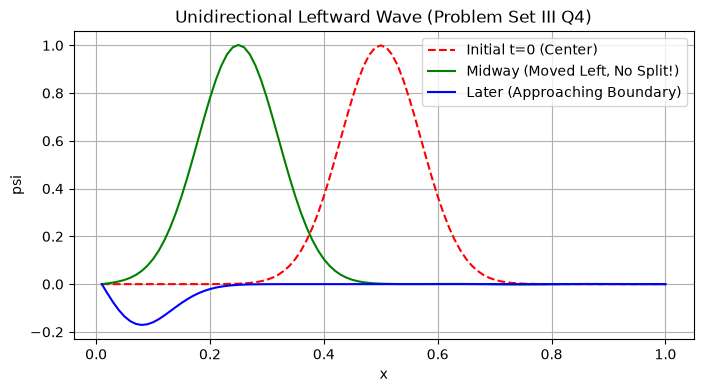

In [5]:
c_speed = 100.0
psi_left = np.exp(-100 * (x - L/2)**2)
psi_left_0 = psi_left.copy()
v_left = -200.0 * c_speed * (x - L/2) * np.exp(-100 * (x - L/2)**2)

# Step 1 with leftward initial velocity
psi_left_1 = np.zeros(N)
for i in range(1, N - 1):
    psi_left_1[i] = (k**2 / 2) * (psi_left[i+1] + psi_left[i-1]) + (1 - k**2) * psi_left[i] + dt * v_left[i]

psi_prev_l = psi_left.copy()
psi_curr_l = psi_left_1.copy()
left_history = [psi_prev_l.copy(), psi_curr_l.copy()]

for step in range(2, 60):
    psi_next_l = np.zeros(N)
    for i in range(1, N - 1):
        psi_next_l[i] = (k**2)*(psi_curr_l[i+1] + psi_curr_l[i-1]) + 2*(1-k**2)*psi_curr_l[i] - psi_prev_l[i]
    psi_prev_l = psi_curr_l.copy()
    psi_curr_l = psi_next_l.copy()
    left_history.append(psi_curr_l.copy())

plt.figure(figsize=(8, 4))
plt.plot(x, psi_left_0, 'r--', label='Initial t=0 (Center)')
plt.plot(x, left_history[25], 'g-', label='Midway (Moved Left, No Split!)')
plt.plot(x, left_history[50], 'b-', label='Later (Approaching Boundary)')
plt.xlabel('x'); plt.ylabel('psi'); plt.title('Unidirectional Leftward Wave (Problem Set III Q4)')
plt.legend(); plt.grid(True); plt.show()
